# Laboratorio 14: detección de comunidades mediante grafos KNN de imágenes (H&M)

Grupo 4:
- Ricardo Amiel Acuña Villogas.
- Juan Leibniz Aquino Espinoza.
- Camilo Ernesto Soto Cristóbal.

In [1]:
import os, json, time, random, base64, io, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
from PIL import Image
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score as ARI, normalized_mutual_info_score as NMI
warnings.filterwarnings("ignore")

BASE = Path.cwd()                       # carpeta S14/Evaluado
DATA = BASE / "data"                    # imágenes descargadas (data/raw/images/...)
FIGS = BASE / "figs"
FIGS.mkdir(exist_ok=True)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA)
REPO = "einrafh/hnm-fashion-recommendations-data"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def guardar(fig, nombre):
    """Guarda la figura en PNG (informe) y PDF (vectorial)."""
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight")
    fig.savefig(FIGS / f"{nombre}.pdf", bbox_inches="tight")

## Parte 1. Muestra, representaciones y grafo KNN

### 1.1 Muestra

Se eligen diez tipos de prenda visualmente distintos entre los más frecuentes del catálogo: Trousers, Dress, Sweater, T-shirt, Shorts, Sneakers, Bag, Hat/beanie, Sunglasses y Socks. Para evitar vecinos casi idénticos se conserva **un solo artículo por product_code** (las variantes de color de una misma prenda); el catálogo se baraja antes de quitar duplicados para no quedarse siempre con la primera variante, que suele ser negra. Se toman 240 candidatos por tipo para cubrir los artículos sin imagen y se dejan 200 por tipo.

In [2]:
TIPOS = ["Trousers", "Dress", "Sweater", "T-shirt", "Shorts",
         "Sneakers", "Bag", "Hat/beanie", "Sunglasses", "Socks"]
N_POR_TIPO = 200          # artículos finales por tipo
MARGEN = 40               # candidatos extra por si falta la imagen

art = pd.read_csv(BASE / "articles.csv", dtype={"article_id": str, "product_code": str})
print("Catálogo completo:", art.shape)

# Se baraja antes de quitar duplicados para no quedarse siempre con la primera variante de color.
cand = (art[art.product_type_name.isin(TIPOS)]
        .sample(frac=1, random_state=SEMILLA)
        .drop_duplicates("product_code"))          # un artículo por product_code
cand = cand.groupby("product_type_name", group_keys=False).head(N_POR_TIPO + MARGEN)
print("Candidatos (un artículo por product_code):", len(cand))

def ruta_imagen(article_id):
    s = str(article_id).zfill(10)
    return f"data/raw/images/{s[:3]}/{s}.jpg"

Catálogo completo: (105542, 25)
Candidatos (un artículo por product_code): 2400


Solo se descargan las imágenes de la muestra, con hf_hub_download y 16 hilos. Si un archivo ya existe en data/raw/images no se vuelve a pedir.

In [3]:
from huggingface_hub import hf_hub_download

def descargar(aid):
    destino = BASE / ruta_imagen(aid)
    if destino.exists():
        return aid, True
    try:
        hf_hub_download(REPO, ruta_imagen(aid), repo_type="dataset", local_dir=BASE)
        return aid, True
    except Exception:
        return aid, False                         # artículo sin imagen

t0 = time.time()
with ThreadPoolExecutor(16) as ex:
    estado = dict(ex.map(descargar, cand.article_id))
cand["tiene_imagen"] = cand.article_id.map(estado)
print(f"Descarga terminada en {time.time() - t0:.0f} s; sin imagen: {(~cand.tiene_imagen).sum()}")

muestra = (cand[cand.tiene_imagen]
           .groupby("product_type_name", group_keys=False).head(N_POR_TIPO)
           .reset_index(drop=True))
muestra["ruta"] = muestra.article_id.map(ruta_imagen)
print("Tamaño final de la muestra:", len(muestra))
muestra.product_type_name.value_counts()

Descarga terminada en 1 s; sin imagen: 38
Tamaño final de la muestra: 2000


product_type_name
Sneakers      200
T-shirt       200
Sweater       200
Shorts        200
Dress         200
Trousers      200
Socks         200
Sunglasses    200
Hat/beanie    200
Bag           200
Name: count, dtype: int64

De los 2400 candidatos, 38 no tienen imagen y se descartan. La muestra final tiene **2000 artículos, 200 por tipo**.

Figura 1: **Ocho artículos por tipo de prenda de la muestra**

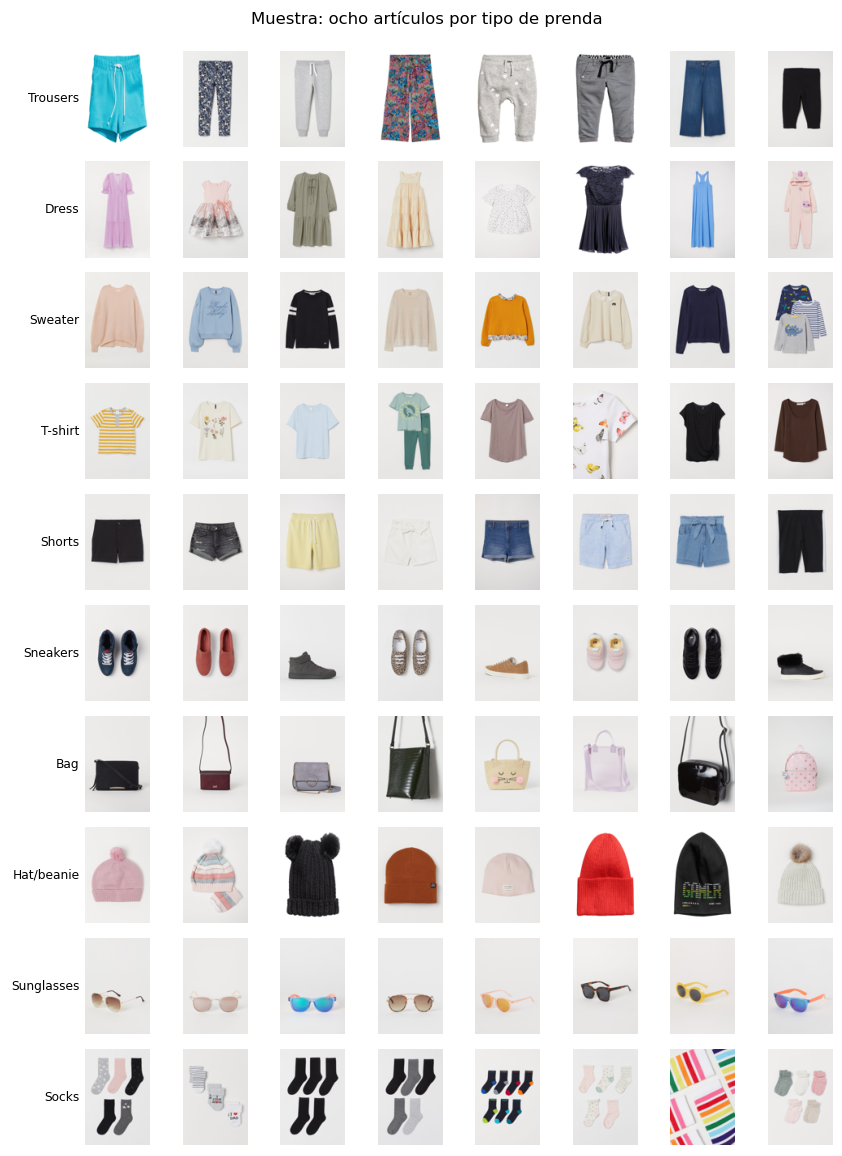

In [4]:
fig, ejes = plt.subplots(len(TIPOS), 8, figsize=(8, 10.5))
for i, t in enumerate(TIPOS):
    filas = muestra[muestra.product_type_name == t].head(8)
    for j, (_, r) in enumerate(filas.iterrows()):
        ax = ejes[i, j]
        ax.imshow(Image.open(BASE / r.ruta).convert("RGB").resize((80, 120)))
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if j == 0: ax.set_ylabel(t, rotation=0, ha="right", va="center", fontsize=8)
fig.suptitle("Muestra: ocho artículos por tipo de prenda", y=0.995)
fig.tight_layout(); guardar(fig, "fig01_muestra"); plt.show()

La figura sirve para ver cómo son las fotos antes de medir nada. Casi todas muestran la prenda sola, centrada y sobre un fondo gris muy claro, y solo unas pocas son primeros planos o tienen fondo de color. Por eso el fondo casi no varía entre tipos, y la diferencia entre fotos la ponen la silueta y el color de la prenda.

### 1.2 Representaciones

1. **Píxeles:** la imagen se reduce a 32 × 32 × 3 y se aplana en un vector de 3072 valores entre 0 y 1. Para los vecinos se usa la distancia euclidiana.
2. **CNN:** ResNet-50 preentrenada en ImageNet con la capa fc reemplazada por la identidad, lo que da la salida del average pooling previa al clasificador, de 2048 dimensiones. Para los vecinos se usa la distancia coseno.

En la misma pasada se guarda una miniatura en base64 para la visualización y un indicador de fondo: la **fracción de píxeles casi blancos en el borde** de la foto. Este valor es alto cuando la prenda está sola sobre fondo claro y bajo en primeros planos o fotos con fondo de color.

In [5]:
import torch, torchvision
torch.set_num_threads(os.cpu_count())

def fondo_blanco(img):
    """Fracción de píxeles casi blancos en el borde: alta en fotos de prenda sola sobre fondo claro."""
    a = np.asarray(img.resize((64, 96)), dtype=np.int16)
    borde = np.concatenate([a[:6].reshape(-1, 3), a[-6:].reshape(-1, 3),
                            a[:, :5].reshape(-1, 3), a[:, -5:].reshape(-1, 3)])
    return float((borde.min(axis=1) > 225).mean())

pesos = torchvision.models.ResNet50_Weights.DEFAULT
cnn = torchvision.models.resnet50(weights=pesos)
cnn.fc = torch.nn.Identity()                 # salida previa al clasificador, 2048 dims
cnn.eval()
prep = pesos.transforms()
X_pix, X_cnn, fb, thumbs = [], [], [], []
lote = []
t0 = time.time()
for i, r in enumerate(muestra.itertuples()):
    img = Image.open(BASE / r.ruta).convert("RGB")
    X_pix.append(np.asarray(img.resize((32, 32)), dtype=np.float32).ravel() / 255.0)
    fb.append(fondo_blanco(img))
    buf = io.BytesIO(); img.resize((56, 84)).save(buf, "JPEG", quality=72)
    thumbs.append(base64.b64encode(buf.getvalue()).decode())
    lote.append(prep(img))
    if len(lote) == 32 or i == len(muestra) - 1:
        with torch.no_grad():
            X_cnn.append(cnn(torch.stack(lote)).numpy())
        lote = []
X_pix, X_cnn = np.stack(X_pix), np.concatenate(X_cnn)
aux = pd.DataFrame({"article_id": muestra.article_id, "fondo_blanco": fb, "thumb": thumbs})
print(f"Representaciones calculadas en {time.time() - t0:.0f} s")


muestra["fondo_blanco"] = aux.fondo_blanco.values
print("Píxeles:", X_pix.shape, " CNN:", X_cnn.shape)

Representaciones calculadas en 324 s
Píxeles: (2000, 3072)  CNN: (2000, 2048)


### 1.3 Grafo KNN

Cada artículo es un nodo con los atributos pedidos (article_id, prod_name, product_type_name, product_group_name, colour_group_name, perceived_colour_master_name, graphical_appearance_name y la ruta de la imagen). Se usa un **grafo no dirigido** con la regla de unión: hay arista entre i y j si j está entre los k vecinos de i o i entre los de j. La relación KNN no es simétrica, y la unión evita que un artículo quede aislado solo porque nadie lo eligió como vecino. Además, Louvain y la modularidad de NetworkX trabajan sobre grafos no dirigidos. Las aristas no llevan peso: la vecindad ya codifica la similitud, y los cosenos entre embeddings CNN varían en un rango estrecho que aportaría poca información adicional.

In [6]:
ATRIBUTOS = ["article_id", "prod_name", "product_type_name", "product_group_name", "colour_group_name",
             "perceived_colour_master_name", "graphical_appearance_name", "ruta"]
KS = [3, 5, 10, 20]
REPS = {"CNN": (X_cnn, "cosine"), "Píxeles": (X_pix, "euclidean")}

def vecinos(X, metrica, kmax=max(KS)):
    nn = NearestNeighbors(n_neighbors=kmax + 1, metric=metrica).fit(X)
    dist, idx = nn.kneighbors(X)
    return dist[:, 1:], idx[:, 1:]               # se descarta el propio punto

def grafo_knn(idx, k):
    """Grafo no dirigido: arista (i, j) si j está entre los k vecinos de i o i entre los de j."""
    G = nx.Graph()
    for i, fila in enumerate(muestra[ATRIBUTOS].to_dict("records")):
        G.add_node(i, **fila)
    G.add_edges_from((i, int(j)) for i in range(len(idx)) for j in idx[i, :k])
    return G

VEC = {rep: vecinos(X, m) for rep, (X, m) in REPS.items()}
GRAFOS = {(rep, k): grafo_knn(VEC[rep][1], k) for rep in REPS for k in KS}
for (rep, k), G in GRAFOS.items():
    print(f"{rep:8s} k={k:2d}: {G.number_of_nodes()} nodos, {G.number_of_edges():6d} aristas, "
          f"componentes={nx.number_connected_components(G)}")

CNN      k= 3: 2000 nodos,   4793 aristas, componentes=2
CNN      k= 5: 2000 nodos,   7835 aristas, componentes=2
CNN      k=10: 2000 nodos,  15379 aristas, componentes=1
CNN      k=20: 2000 nodos,  29979 aristas, componentes=1
Píxeles  k= 3: 2000 nodos,   4969 aristas, componentes=2
Píxeles  k= 5: 2000 nodos,   8205 aristas, componentes=1
Píxeles  k=10: 2000 nodos,  16250 aristas, componentes=1
Píxeles  k=20: 2000 nodos,  32447 aristas, componentes=1


Con k = 3 y k = 5 el grafo CNN tiene dos componentes: las 200 gafas de sol (Sunglasses) forman una isla que solo se conecta al resto con k = 10 o más. El número de aristas queda por debajo de 2000 × k porque las relaciones mutuas se cuentan una sola vez.

## Parte 2. Comunidades con Louvain y visualización del grafo

Se aplica louvain_communities (semilla 42) a los ocho grafos. Para verificar Q se mide la modularidad de dos particiones de referencia sobre el mismo grafo: la que da product_type_name y una partición aleatoria con los mismos tamaños que la de Louvain, que debe dar Q cercana a 0. También se registran el ARI y el NMI frente a los atributos del catálogo.

In [7]:
def particion_a_etiquetas(comunidades, n):
    etiq = np.empty(n, dtype=int)
    for c, nodos in enumerate(sorted(comunidades, key=len, reverse=True)):
        etiq[list(nodos)] = c                     # comunidad 0 es la más grande
    return etiq

def etiquetas_a_particion(etiq):
    return [set(np.flatnonzero(etiq == c)) for c in np.unique(etiq)]

def q_de(G, etiq):
    return nx.community.modularity(G, etiquetas_a_particion(np.asarray(etiq)))

y_tipo = muestra.product_type_name.values
y_color = muestra.perceived_colour_master_name.values
y_patron = muestra.graphical_appearance_name.values
rng = np.random.default_rng(SEMILLA)

filas, COM = [], {}
for (rep, k), G in GRAFOS.items():
    com = nx.community.louvain_communities(G, seed=SEMILLA)
    etiq = particion_a_etiquetas(com, G.number_of_nodes())
    COM[(rep, k)] = etiq
    filas.append({"rep": rep, "k": k, "aristas": G.number_of_edges(),
                  "densidad": nx.density(G), "grado_medio": 2 * G.number_of_edges() / G.number_of_nodes(),
                  "n_com": len(com), "Q_louvain": q_de(G, etiq),
                  "Q_tipo": q_de(G, pd.factorize(y_tipo)[0]),
                  "Q_azar": q_de(G, rng.permutation(etiq)),      # mismos tamaños, nodos al azar
                  "ARI_tipo": ARI(y_tipo, etiq), "NMI_tipo": NMI(y_tipo, etiq),
                  "ARI_color": ARI(y_color, etiq), "NMI_color": NMI(y_color, etiq),
                  "NMI_patron": NMI(y_patron, etiq)})
tabla_k = pd.DataFrame(filas)
tabla_k.round(3)

,rep,k,aristas,densidad,grado_medio,n_com,Q_louvain,Q_tipo,Q_azar,ARI_tipo,NMI_tipo,ARI_color,NMI_color,NMI_patron
0,CNN,3,4793,0.002,4.793,17,0.871,0.775,0.002,0.617,0.736,0.021,0.099,0.195
1,CNN,5,7835,0.004,7.835,14,0.852,0.770,-0.004,0.689,0.771,0.023,0.094,0.185
2,CNN,10,15379,0.008,15.379,12,0.836,0.762,-0.002,0.739,0.796,0.026,0.094,0.175
3,CNN,20,29979,0.015,29.979,11,0.817,0.745,0.002,0.762,0.807,0.023,0.080,0.159
4,Píxeles,3,4969,0.002,4.969,25,0.813,0.480,0.002,0.164,0.347,0.052,0.168,0.110
5,Píxeles,5,8205,0.004,8.205,21,0.772,0.439,0.003,0.162,0.336,0.056,0.179,0.106
6,Píxeles,10,16250,0.008,16.250,14,0.724,0.387,-0.001,0.148,0.312,0.058,0.162,0.090
7,Píxeles,20,32447,0.016,32.447,12,0.680,0.320,0.000,0.136,0.285,0.078,0.174,0.080


La verificación se cumple en los ocho grafos: la partición aleatoria da Q entre −0.004 y 0.003, y Louvain siempre supera a la partición por tipo. En el grafo CNN la partición por tipo ya es muy modular (Q de 0.745 a 0.775), es decir, los vecinos CNN suelen ser del mismo tipo. En el grafo de píxeles esa Q baja a valores entre 0.320 y 0.480, aunque Louvain encuentre comunidades con Q de 0.680 a 0.813: ahí hay estructura, pero no es la del tipo de prenda.

El **mejor k** se elige con el **método del codo** sobre la curva de acuerdo con el ground truth (NMI entre las comunidades y product_type_name): es el menor k a partir del cual subir k mejora el NMI en menos de un 2 % relativo. Q no sirve para elegir k porque siempre favorece al k menor, y el máximo del NMI premia diferencias marginales a cambio de un grafo mucho más denso y menos interpretable. En CNN las ganancias son de 4.8 %, 3.2 % y 1.4 %, por lo que el codo está en **k = 10** (NMI de 0.796, frente a 0.807 del máximo en k = 20, con la mitad de aristas). En píxeles el NMI baja desde el primer paso, así que el codo coincide con el máximo en **k = 3**.

In [8]:
# Mejor k por el método del codo sobre el acuerdo con el ground truth (NMI con product_type_name):
# el menor k a partir del cual subir k mejora el NMI menos de un 2 % relativo.
UMBRAL_CODO = 0.02

def k_codo(d):
    d = d.sort_values("k"); ks, v = d.k.values, d.NMI_tipo.values
    for i in range(1, len(v)):
        if (v[i] - v[i - 1]) / v[i - 1] < UMBRAL_CODO:
            return int(ks[i - 1])
    return int(ks[-1])

MEJOR_K = {rep: k_codo(d) for rep, d in tabla_k.groupby("rep")}
K_MAX = {rep: int(d.loc[d.NMI_tipo.idxmax(), "k"]) for rep, d in tabla_k.groupby("rep")}
for rep, d in tabla_k.groupby("rep"):
    v = d.sort_values("k").NMI_tipo.values
    print(rep, "ganancia relativa del NMI entre k consecutivos:", [f"{(b - a) / a:+.1%}" for a, b in zip(v, v[1:])])
print("k por el codo:", MEJOR_K, " k del máximo NMI (contraste):", K_MAX)

CNN ganancia relativa del NMI entre k consecutivos: ['+4.8%', '+3.2%', '+1.4%']
Píxeles ganancia relativa del NMI entre k consecutivos: ['-3.2%', '-6.9%', '-8.7%']
k por el codo: {'CNN': 10, 'Píxeles': 3}  k del máximo NMI (contraste): {'CNN': 20, 'Píxeles': 3}


Figura 2: **Efecto de k sobre las aristas, la densidad, el número de comunidades, la modularidad y el NMI**

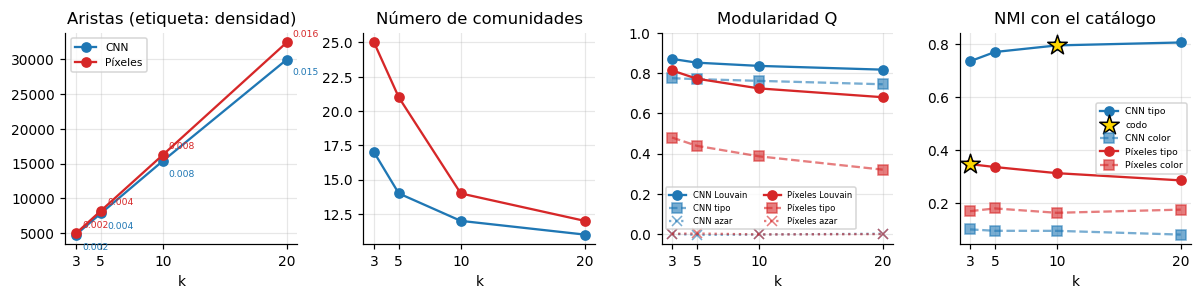

In [9]:
fig, ejes = plt.subplots(1, 4, figsize=(11, 2.8))
colores_rep = {"CNN": "#1f77b4", "Píxeles": "#d62728"}
for rep, d in tabla_k.groupby("rep"):
    c = colores_rep[rep]
    ejes[0].plot(d.k, d.aristas, "o-", c=c, label=rep)
    for r in d.itertuples():
        ejes[0].annotate(f"{r.densidad:.3f}", (r.k, r.aristas), textcoords="offset points",
                         xytext=(4, -10 if rep == "CNN" else 4), fontsize=6, c=c)
    ejes[1].plot(d.k, d.n_com, "o-", c=c, label=rep)
    ejes[2].plot(d.k, d.Q_louvain, "o-", c=c, label=f"{rep} Louvain")
    ejes[2].plot(d.k, d.Q_tipo, "s--", c=c, alpha=.6, label=f"{rep} tipo")
    ejes[2].plot(d.k, d.Q_azar, "x:", c=c, alpha=.6, label=f"{rep} azar")
    ejes[3].plot(d.k, d.NMI_tipo, "o-", c=c, label=f"{rep} tipo")
    kc = MEJOR_K[rep]; vc = d.loc[d.k == kc, "NMI_tipo"].iloc[0]
    ejes[3].scatter([kc], [vc], s=180, marker="*", c="gold", edgecolors="k", zorder=5,
                    label="codo" if rep == "CNN" else None)
    ejes[3].plot(d.k, d.NMI_color, "s--", c=c, alpha=.6, label=f"{rep} color")
titulos = ["Aristas (etiqueta: densidad)", "Número de comunidades", "Modularidad Q", "NMI con el catálogo"]
for ax, t in zip(ejes, titulos):
    ax.set_title(t); ax.set_xlabel("k"); ax.set_xticks(KS); ax.grid(alpha=.3)
ejes[0].legend(fontsize=7); ejes[2].set_ylim(-.05, 1)
ejes[2].legend(fontsize=5.5, ncol=2, loc="lower left", bbox_to_anchor=(0, .05)); ejes[3].legend(fontsize=6)
fig.tight_layout(); guardar(fig, "fig02_efecto_k"); plt.show()

Las aristas crecen casi en proporción a k y la densidad pasa de 0.002 a 0.015. Al haber más aristas entre grupos, Q baja y Louvain fusiona comunidades: de 17 a 11 en CNN y de 25 a 12 en píxeles. El NMI con el tipo se mueve en sentidos opuestos. En CNN sube de 0.736 a 0.807, pero casi toda la mejora ocurre antes de k = 10, y la estrella marca el codo. En píxeles baja de 0.347 a 0.285, porque los vecinos adicionales son ruido.

Se calcula un spring_layout (semilla 42, 80 iteraciones) por grafo y se reutiliza en todas las vistas del mismo grafo. Las aristas se dibujan con una transparencia inversa a su número para que los grafos densos sigan siendo legibles.

In [10]:
claves = [(rep, k) for rep in REPS for k in KS]
POS, t0 = {}, time.time()
for c in claves:
    p = nx.spring_layout(GRAFOS[c], seed=SEMILLA, iterations=80)
    POS[c] = np.array([p[i] for i in range(len(p))])
print(f"Layouts en {time.time() - t0:.0f} s")

PAL_TIPO = dict(zip(TIPOS, plt.cm.tab10.colors))
PAL_COLOR = {"Black": "#222222", "White": "#f2f2f2", "Grey": "#9a9a9a", "Blue": "#2b5fb4",
             "Beige": "#d8c3a0", "Pink": "#f19cbb", "Red": "#d02a2a", "Khaki green": "#7d7d4a",
             "Brown": "#7b4a2a", "Green": "#3a9a4a", "Orange": "#f08a24", "Yellow": "#f2d23c",
             "Turquoise": "#2fb8b0", "Lilac Purple": "#9b6fc0", "Metal": "#b8b8c8",
             "Mole": "#8a7d70", "Yellowish Green": "#b5c93a", "Bluish Green": "#3a8f80",
             "undefined": "#ffffff", "Unknown": "#ffffff"}

def colores_comunidad(etiq):
    base = list(plt.cm.tab20.colors)
    return [base[e % 20] for e in etiq]

def dibujar(ax, G, pos, colores, titulo, alfa_arista=None):
    if alfa_arista is None:
        alfa_arista = min(.05, 400 / G.number_of_edges())   # menos opacas cuanto más aristas
    seg = np.array([(pos[u], pos[v]) for u, v in G.edges()])
    ax.add_collection(mpl.collections.LineCollection(seg, colors="k", linewidths=.3, alpha=alfa_arista))
    ax.scatter(pos[:, 0], pos[:, 1], c=colores, s=5, linewidths=.15, edgecolors="#555")
    ax.set_title(titulo, fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for s in ax.spines.values(): s.set_visible(False)

Layouts en 130 s


Figura 3: **Grafos KNN para k = 3, 5, 10 y 20 en ambas representaciones, coloreados por tipo de prenda**

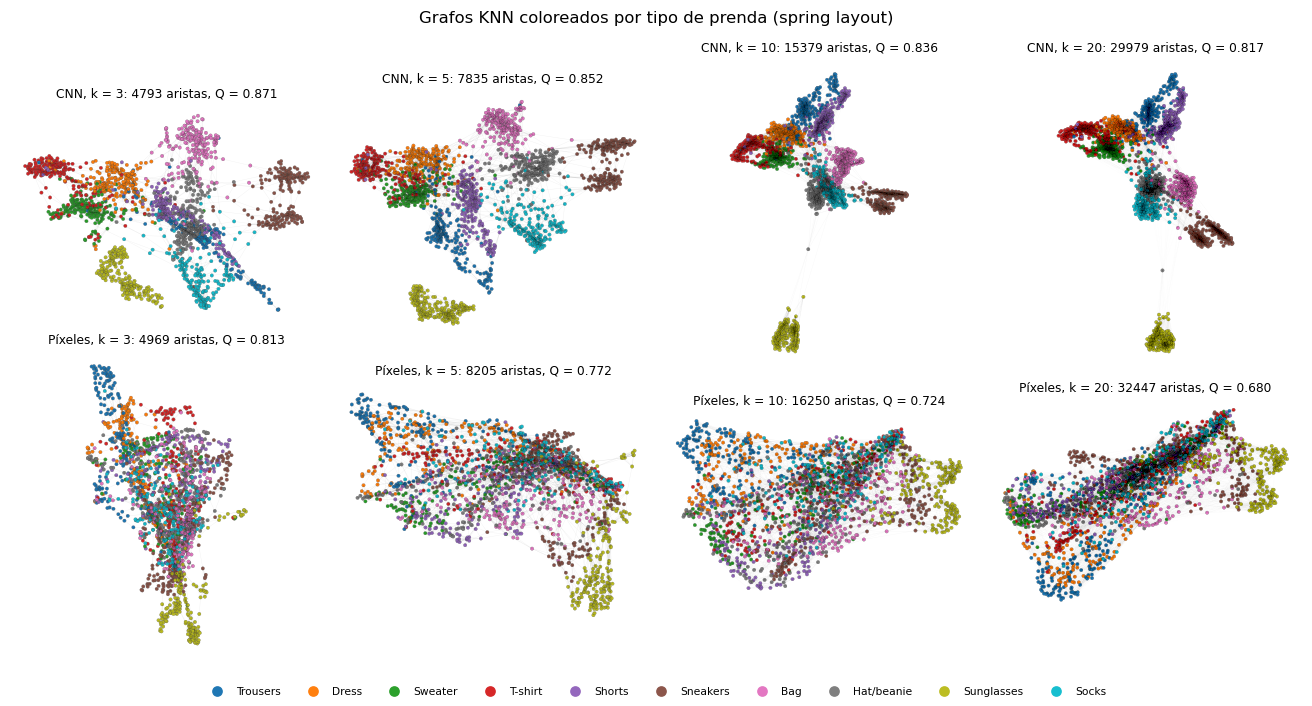

In [11]:
fig, ejes = plt.subplots(2, 4, figsize=(12, 6.4))
for i, rep in enumerate(REPS):
    for j, k in enumerate(KS):
        f = tabla_k[(tabla_k.rep == rep) & (tabla_k.k == k)].iloc[0]
        dibujar(ejes[i, j], GRAFOS[(rep, k)], POS[(rep, k)], [PAL_TIPO[t] for t in y_tipo],
                f"{rep}, k = {k}: {f.aristas} aristas, Q = {f.Q_louvain:.3f}")
manijas = [mpl.lines.Line2D([], [], marker="o", ls="", color=PAL_TIPO[t], label=t) for t in TIPOS]
fig.legend(handles=manijas, loc="lower center", ncol=10, fontsize=7, frameon=False)
fig.suptitle("Grafos KNN coloreados por tipo de prenda (spring layout)")
fig.tight_layout(rect=(0, .04, 1, 1)); guardar(fig, "fig03_grafos_por_k"); plt.show()

En la fila CNN cada color forma una región compacta para cualquier k, y la separación entre tipos se conserva aunque el grafo se densifique. Sunglasses aparece como una isla en todos los paneles. En la fila de píxeles los colores se mezclan en un núcleo central, y al subir k el grafo se contrae y la separación empeora. Solo Sunglasses, Trousers y una parte de Bag mantienen zonas propias.

Figura 4: **Mejor grafo de cada representación coloreado por comunidad, por tipo de prenda y por color percibido, con el mismo layout**

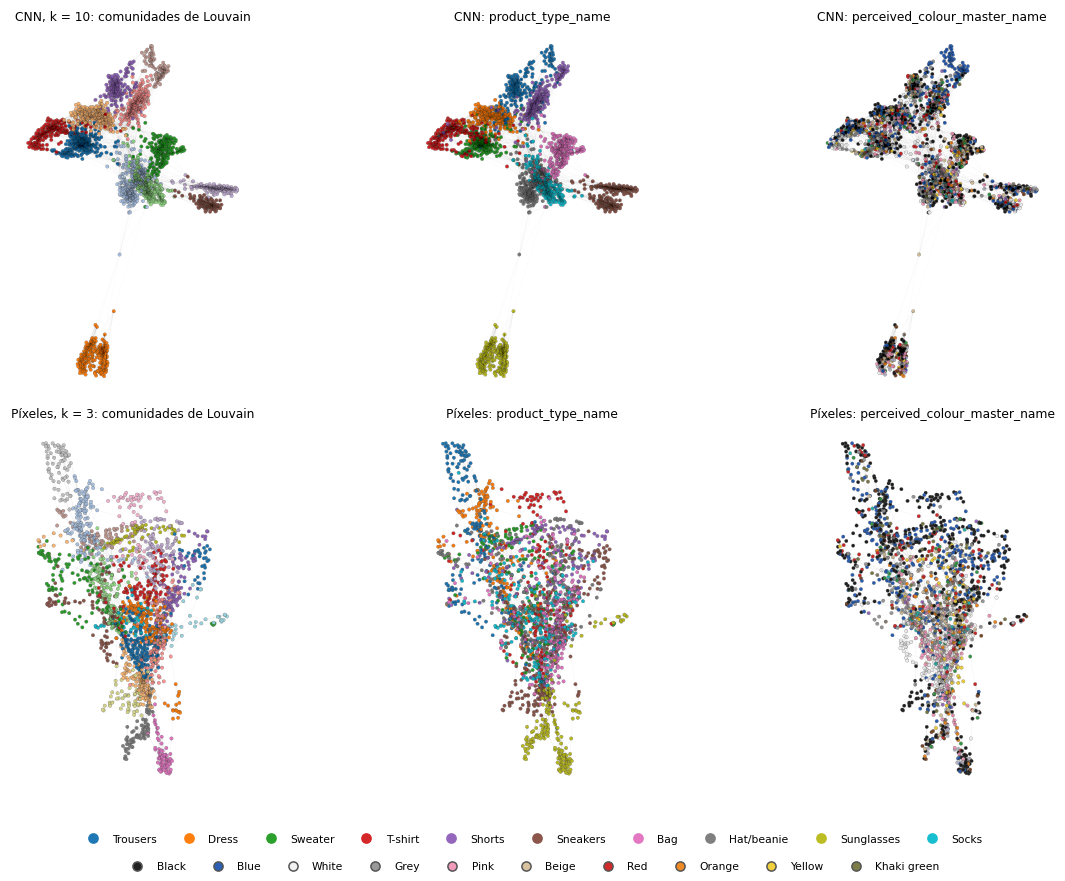

In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 8))
for i, rep in enumerate(REPS):
    c = (rep, MEJOR_K[rep]); G, pos = GRAFOS[c], POS[c]
    dibujar(ejes[i, 0], G, pos, colores_comunidad(COM[c]), f"{rep}, k = {c[1]}: comunidades de Louvain")
    dibujar(ejes[i, 1], G, pos, [PAL_TIPO[t] for t in y_tipo], f"{rep}: product_type_name")
    dibujar(ejes[i, 2], G, pos, [PAL_COLOR.get(t, "#fff") for t in y_color], f"{rep}: perceived_colour_master_name")
top_colores = pd.Series(y_color).value_counts().index[:10]
manijas_color = [mpl.lines.Line2D([], [], marker="o", ls="", color=PAL_COLOR.get(t, "#fff"), markeredgecolor="#555",
                                  label=t) for t in top_colores]
fig.legend(handles=manijas, loc="lower center", ncol=10, fontsize=7, frameon=False, bbox_to_anchor=(.5, .025))
fig.legend(handles=manijas_color, loc="lower center", ncol=10, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, .08, 1, 1)); guardar(fig, "fig04_grafo_tres_vistas"); plt.show()

En CNN (k = 10) el panel de comunidades y el de tipos son casi el mismo dibujo, mientras que el de color no muestra ningún patrón: el negro y el azul aparecen en todas las regiones. En píxeles (k = 3) las comunidades no coinciden con los tipos, y el panel de color sí muestra una tendencia: la parte superior es oscura y la inferior concentra blancos, rosados y beige. En píxeles el grafo se ordena más por luminosidad que por forma.

## Parte 3. K-Means, Node2Vec y visualización interactiva

### 3.1 Louvain frente a K-Means

K-Means usa K = 10 (el número de tipos de la muestra) y 10 inicializaciones sobre los mismos vectores que generaron el grafo. Para CNN los vectores se normalizan a norma 1, de modo que la distancia euclidiana que usa K-Means equivale a la distancia coseno del grafo. La Q de K-Means se mide sobre el grafo KNN del mejor k.

In [13]:
filas = []
ETIQ = {}                                   # todas las particiones del mejor k
for rep, (X, m) in REPS.items():
    c = (rep, MEJOR_K[rep]); G = GRAFOS[c]
    Xk = X / np.linalg.norm(X, axis=1, keepdims=True) if m == "cosine" else X   # euclidiana en la esfera ~ coseno
    km = KMeans(n_clusters=len(TIPOS), n_init=10, random_state=SEMILLA).fit_predict(Xk)
    ETIQ[f"Louvain {rep}"], ETIQ[f"K-Means {rep}"] = COM[c], km
    for metodo, e in [("Louvain", COM[c]), ("K-Means", km)]:
        tam = np.bincount(e)
        filas.append({"rep": rep, "k": c[1], "método": metodo, "grupos": len(tam),
                      "mayor": tam.max(), "menor": tam.min(), "cv_tamaño": tam.std() / tam.mean(),
                      "Q_grafo": q_de(G, e),
                      "ARI_tipo": ARI(y_tipo, e), "NMI_tipo": NMI(y_tipo, e),
                      "ARI_color": ARI(y_color, e), "NMI_color": NMI(y_color, e),
                      "NMI_patron": NMI(y_patron, e)})
tabla_metodos = pd.DataFrame(filas)
for rep in REPS:
    a, b = ETIQ[f"Louvain {rep}"], ETIQ[f"K-Means {rep}"]
    print(f"{rep}: acuerdo entre Louvain y K-Means, ARI = {ARI(a, b):.3f}, NMI = {NMI(a, b):.3f}")
tabla_metodos.round(3)

CNN: acuerdo entre Louvain y K-Means, ARI = 0.806, NMI = 0.849
Píxeles: acuerdo entre Louvain y K-Means, ARI = 0.230, NMI = 0.496


,rep,k,método,grupos,mayor,menor,cv_tamaño,Q_grafo,ARI_tipo,NMI_tipo,ARI_color,NMI_color,NMI_patron
0,CNN,10,Louvain,12,234,77,0.293,0.836,0.739,0.796,0.026,0.094,0.175
1,CNN,10,K-Means,10,250,162,0.135,0.814,0.782,0.821,0.024,0.080,0.152
2,Píxeles,3,Louvain,25,191,5,0.569,0.813,0.164,0.347,0.052,0.168,0.110
3,Píxeles,3,K-Means,10,536,49,0.695,0.670,0.083,0.210,0.070,0.172,0.071


En CNN ambos métodos se parecen mucho (ARI entre ellos de 0.806). K-Means queda algo por encima en ARI y NMI con el tipo (0.782 y 0.821, frente a 0.739 y 0.796), y Louvain queda por encima en Q (0.836 frente a 0.814). En píxeles las dos particiones se parecen poco (ARI entre ellas de 0.230). Louvain obtiene un NMI con el tipo de 0.347 frente a 0.210 de K-Means y una Q de 0.813 frente a 0.670.

Figura 5: **Louvain frente a K-Means: acuerdo con el catálogo, modularidad en el grafo KNN y tamaño de los grupos**

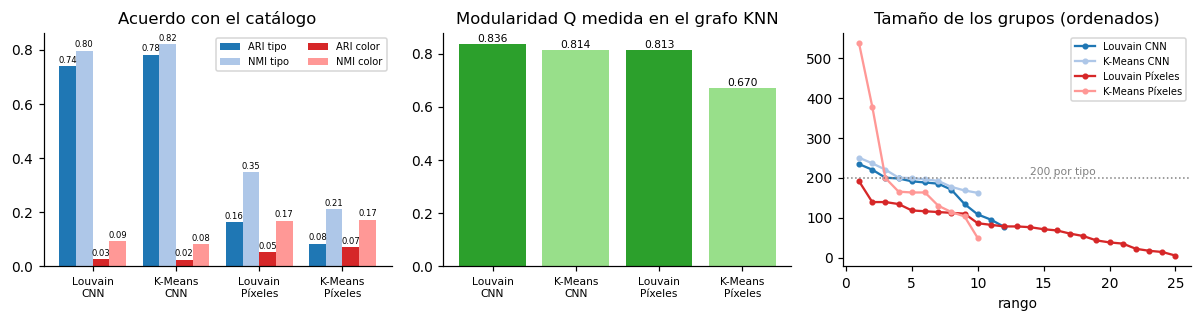

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 3))
etiq_barras = [f"{r.método}\n{r.rep}" for r in tabla_metodos.itertuples()]
x = np.arange(len(tabla_metodos)); w = .2
for d, (col, lab, c) in enumerate([("ARI_tipo", "ARI tipo", "#1f77b4"), ("NMI_tipo", "NMI tipo", "#aec7e8"),
                                    ("ARI_color", "ARI color", "#d62728"), ("NMI_color", "NMI color", "#ff9896")]):
    b = ejes[0].bar(x + (d - 1.5) * w, tabla_metodos[col], w, color=c, label=lab)
    ejes[0].bar_label(b, fmt="%.2f", fontsize=5.5, padding=1)
ejes[0].set_xticks(x, etiq_barras, fontsize=7); ejes[0].legend(fontsize=6.5, ncol=2)
ejes[0].set_title("Acuerdo con el catálogo")
b = ejes[1].bar(x, tabla_metodos.Q_grafo, color=["#2ca02c", "#98df8a"] * 2)
ejes[1].bar_label(b, fmt="%.3f", fontsize=7); ejes[1].set_xticks(x, etiq_barras, fontsize=7)
ejes[1].set_title("Modularidad Q medida en el grafo KNN")
for i, (nombre, e) in enumerate(ETIQ.items()):
    tam = np.sort(np.bincount(e))[::-1]
    ejes[2].plot(np.arange(1, len(tam) + 1), tam, "o-", ms=3, label=nombre,
                 c=["#1f77b4", "#aec7e8", "#d62728", "#ff9896"][i])
ejes[2].axhline(N_POR_TIPO, c="gray", ls=":", lw=1); ejes[2].text(14, N_POR_TIPO + 8, "200 por tipo", fontsize=7, c="gray")
ejes[2].set_title("Tamaño de los grupos (ordenados)"); ejes[2].set_xlabel("rango"); ejes[2].legend(fontsize=6.5)
fig.tight_layout(); guardar(fig, "fig05_louvain_vs_kmeans"); plt.show()

El panel de tamaños muestra la diferencia de comportamiento. En CNN K-Means produce diez grupos de entre 162 y 250 artículos. Louvain produce doce, de entre 77 y 234: parte Sneakers en dos comunidades (108 y 95) y separa una comunidad de denim de 77 artículos. En píxeles K-Means forma dos grupos gigantes de 536 y 378 artículos y otro de 49 (coeficiente de variación 0.70), y Louvain reparte los 2000 nodos en 25 comunidades de entre 5 y 191.

### 3.2 Node2Vec

Node2Vec se implementa como en la lectura de la semana: caminatas sesgadas por p y q y luego skip-gram con muestreo negativo (Word2Vec de gensim). Parámetros: r = 10 caminatas por nodo, longitud l = 40, p = 1, q = 0.5 (q menor que 1 favorece el recorrido tipo DFS, que según Grover y Leskovec captura mejor la pertenencia a comunidades), dimensión 64, ventana 5 y 5 negativos. Los vectores de 64 dimensiones se proyectan a 2D con t-SNE (coseno, perplejidad 30). Para comparar los tres espacios, también se aplica t-SNE directamente a los píxeles y a los embeddings CNN.

In [15]:
import zlib
from gensim.models import Word2Vec

def node2vec_caminos(G, r=10, l=40, p=1.0, q=0.5, semilla=SEMILLA):
    """Caminatas sesgadas de Node2Vec (Grover y Leskovec, 2016) sobre un grafo no ponderado.
    Desde v, tras llegar desde t: peso 1/p para volver a t, 1 para vecinos comunes de t y v, 1/q para alejarse."""
    rg = random.Random(semilla)
    vec = {v: list(G.neighbors(v)) for v in G}
    conj = {v: set(n) for v, n in vec.items()}
    caminos = []
    for _ in range(r):
        nodos = list(G); rg.shuffle(nodos)
        for s in nodos:
            camino = [s]
            while len(camino) < l:
                v = camino[-1]
                if not vec[v]: break
                if len(camino) == 1:
                    camino.append(rg.choice(vec[v])); continue
                t = camino[-2]
                pesos = [1 / p if x == t else (1.0 if x in conj[t] else 1 / q) for x in vec[v]]
                camino.append(rg.choices(vec[v], weights=pesos)[0])
            caminos.append([str(x) for x in camino])
    return caminos

def hash_estable(texto):
    """Hash fijo para inicializar Word2Vec: el hash() de Python cambia entre sesiones y haría variar Node2Vec."""
    return zlib.crc32(texto.encode())

N2V, XY, t0 = {}, {}, time.time()
for rep in REPS:
    G = GRAFOS[(rep, MEJOR_K[rep])]
    w2v = Word2Vec(node2vec_caminos(G), vector_size=64, window=5, min_count=0, sg=1,
                   negative=5, epochs=5, workers=1, seed=SEMILLA, hashfxn=hash_estable)
    N2V[rep] = np.stack([w2v.wv[str(i)] for i in range(G.number_of_nodes())])
    XY[rep] = TSNE(2, metric="cosine", perplexity=30, random_state=SEMILLA).fit_transform(N2V[rep])
# t-SNE directo sobre los vectores originales, para contrastar los tres espacios.
XY_CNN_DIRECTO = TSNE(2, metric="cosine", perplexity=30, random_state=SEMILLA).fit_transform(X_cnn)
XY_PIX_DIRECTO = TSNE(2, metric="euclidean", perplexity=30, random_state=SEMILLA).fit_transform(X_pix)
print(f"Node2Vec y t-SNE en {time.time() - t0:.0f} s")


Node2Vec y t-SNE en 55 s


Para comparar los espacios con la misma vara, se aplica el mismo K-Means (K = 10) en cada uno de ellos.

In [16]:
# K-Means con 10 grupos en cada uno de los tres espacios: mismo algoritmo, distinta geometría.
espacios = {"Píxeles (3072 d)": X_pix,
            "CNN ResNet-50 (2048 d)": X_cnn / np.linalg.norm(X_cnn, axis=1, keepdims=True),
            "Node2Vec sobre KNN CNN (64 d)": N2V["CNN"] / np.linalg.norm(N2V["CNN"], axis=1, keepdims=True)}
filas = []
for nombre, X in espacios.items():
    e = KMeans(n_clusters=len(TIPOS), n_init=10, random_state=SEMILLA).fit_predict(X)
    filas.append({"espacio": nombre, "NMI_tipo": NMI(y_tipo, e), "ARI_tipo": ARI(y_tipo, e),
                  "NMI_color": NMI(y_color, e), "Q_grafo_CNN": q_de(GRAFOS[("CNN", MEJOR_K["CNN"])], e)})
tabla_espacios = pd.DataFrame(filas)
tabla_espacios.round(3)

,espacio,NMI_tipo,ARI_tipo,NMI_color,Q_grafo_CNN
0,Píxeles (3072 d),0.210,0.083,0.172,0.265
1,CNN ResNet-50 (2048 d),0.821,0.782,0.080,0.814
2,Node2Vec sobre KNN CNN (64 d),0.828,0.798,0.079,0.832


Figura 6: **Los tres espacios proyectados con t-SNE (píxeles, CNN y Node2Vec del grafo KNN CNN), coloreados por tipo y por color**

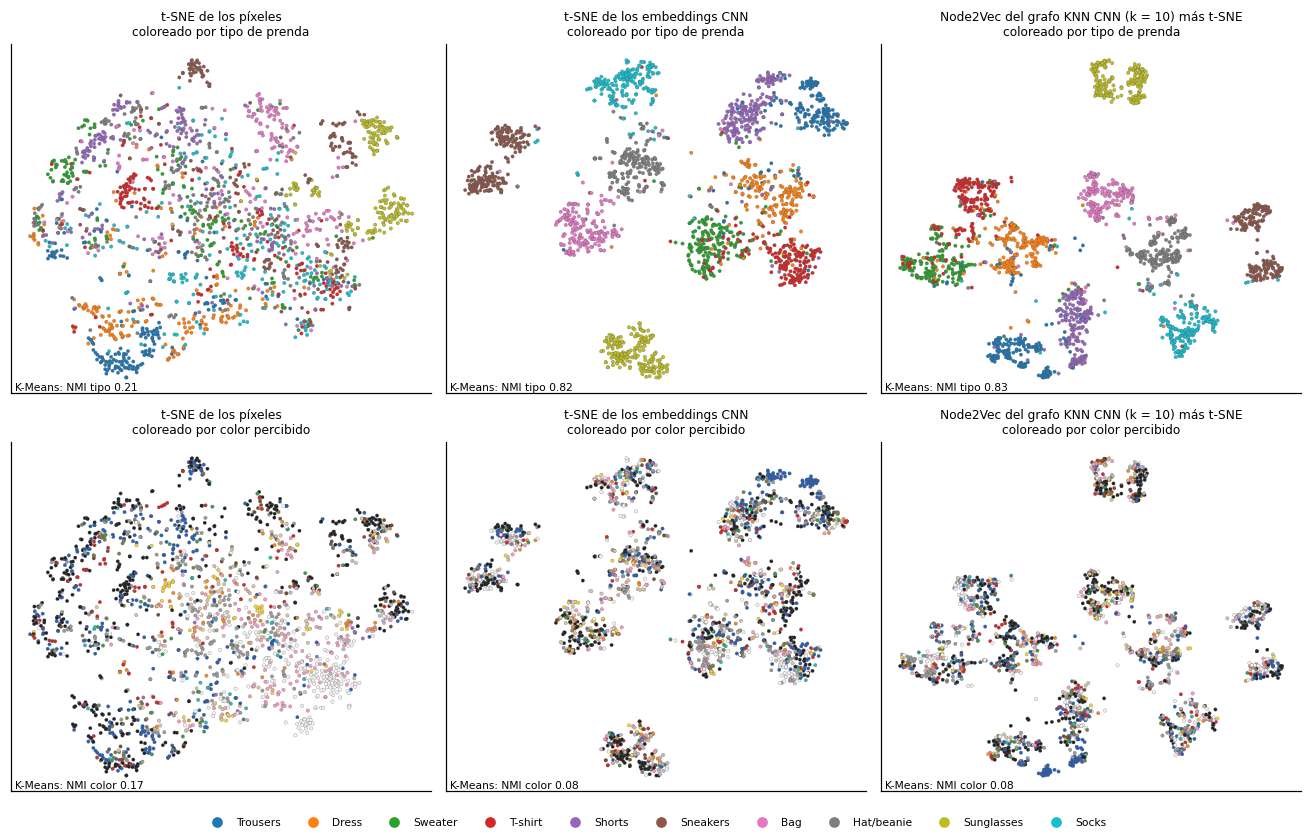

In [17]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 7.6))
vistas = [(XY_PIX_DIRECTO, "t-SNE de los píxeles"), (XY_CNN_DIRECTO, "t-SNE de los embeddings CNN"),
          (XY["CNN"], f"Node2Vec del grafo KNN CNN (k = {MEJOR_K['CNN']}) más t-SNE")]
for j, (xy, titulo) in enumerate(vistas):
    for i, (col, nom) in enumerate([([PAL_TIPO[t] for t in y_tipo], "tipo de prenda"),
                                     ([PAL_COLOR.get(t, "#fff") for t in y_color], "color percibido")]):
        ax = ejes[i, j]
        ax.scatter(xy[:, 0], xy[:, 1], c=col, s=5, linewidths=.15, edgecolors="#555")
        ax.set_title(f"{titulo}\ncoloreado por {nom}", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
        f = tabla_espacios.iloc[j]
        if i == 0: ax.text(.01, .01, f"K-Means: NMI tipo {f.NMI_tipo:.2f}", transform=ax.transAxes, fontsize=7)
        else: ax.text(.01, .01, f"K-Means: NMI color {f.NMI_color:.2f}", transform=ax.transAxes, fontsize=7)
fig.legend(handles=manijas, loc="lower center", ncol=10, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, .03, 1, 1)); guardar(fig, "fig06_tres_espacios"); plt.show()

En el espacio de píxeles los tipos se superponen, salvo Trousers, Sunglasses y Sneakers. El color sí forma un gradiente: los oscuros quedan arriba y a la izquierda, y los claros abajo y a la derecha. En CNN y en Node2Vec aparecen islas por tipo, y el color se reparte al azar dentro de cada una. Node2Vec, con solo 64 dimensiones aprendidas del grafo, iguala a la CNN de 2048 dimensiones (NMI con el tipo de 0.828 frente a 0.821) y separa con más claridad Sweater de T-shirt, y Shorts de Trousers.

### 3.3 Visualización interactiva

La visualización está en viz/index.html (D3 v7, un solo archivo con los datos y las miniaturas incrustados) y se construye a partir del JSON que exporta la celda siguiente. La misma página está en docs/index.html, que es la versión publicada en GitHub Pages (https://ricardoamiel.github.io/Grafo-KNN/). Mecanismo propuesto:

1. **Dos paneles enlazados** con los mismos 2000 artículos. Cada panel elige su posición (Node2Vec del grafo CNN o del grafo de píxeles, o t-SNE directo de cada representación) y su color (Louvain o K-Means de cada representación, product_type_name, perceived_colour_master_name o graphical_appearance_name). Así se puede ver, por ejemplo, Louvain CNN a la izquierda y el tipo de prenda a la derecha sobre la misma geometría.
2. **Tooltip con la miniatura** del artículo y sus atributos al pasar el cursor; el mismo artículo se resalta en el otro panel.
3. **Clic en un nodo:** fija el artículo, dibuja sus k vecinos en ambos paneles y muestra en una tarjeta las imágenes de sus vecinos CNN y de píxeles, con cuántos son del mismo tipo. La tarjeta también controla los gráficos: pasar el cursor sobre un vecino lo ubica en ambos paneles, hacer clic lo fija para seguir recorriendo el grafo, y el botón Ver estos en los gráficos convierte al artículo y sus vecinos en la región activa y hace zoom hasta encuadrarlos.
4. **Tabla cruzada** entre los colores de ambos paneles, con su ARI y NMI calculados en el navegador. Al hacer clic en una celda se resaltan esos artículos.
5. **Selección de una región (brush):** el botón Seleccionar región permite dibujar a mano alzada un contorno (lazo) sobre un panel; al soltar, el modo se apaga solo para que se pueda seguir haciendo clic en los artículos de la región y ver sus vecinos. Los títulos pasan a decir de la región seleccionada, con el número de nodos y de clusters, y las métricas, las leyendas y la tabla cruzada se recalculan solo sobre esos artículos. Además aparece una tabla de Louvain frente a K-Means de la región, con la Q medida en el subgrafo inducido. El botón Restablecer vista (o Esc), ubicado junto a Deshacer en la barra fija sobre los dos gráficos, vuelve al estado original, y Deshacer (o Ctrl+Z) recupera la vista anterior completa: región, artículo fijado, zoom y trazo del lazo. Por ejemplo, tras restablecer, Deshacer devuelve la región que estaba seleccionada.
6. Leyendas que filtran al hacer clic, zoom con la rueda (también en modo selección) y desplazamiento al arrastrar. La curva del efecto de k y la tabla global de Louvain frente a K-Means son fijas, porque resumen los 2000 nodos.

In [18]:
# Exporta los datos para la visualización interactiva en D3 (viz/index.html).
def lista(a): return [int(x) for x in a]
datos = {
    "nodos": [{"id": i, "aid": r.article_id, "nombre": r.prod_name, "tipo": r.product_type_name,
               "grupo": r.product_group_name, "color": r.perceived_colour_master_name,
               "color_grupo": r.colour_group_name, "patron": r.graphical_appearance_name,
               "fondo": round(float(r.fondo_blanco), 2), "img": aux.thumb[i]}
              for i, r in enumerate(muestra.itertuples())],
    "posiciones": {
        "n2v_cnn": XY["CNN"].round(3).tolist(), "n2v_pix": XY["Píxeles"].round(3).tolist(),
        "tsne_cnn": XY_CNN_DIRECTO.round(3).tolist(), "tsne_pix": XY_PIX_DIRECTO.round(3).tolist()},
    "particiones": {nombre: lista(e) for nombre, e in ETIQ.items()},
    "vecinos": {rep: VEC[rep][1][:, :MEJOR_K[rep]].tolist() for rep in REPS},
    "mejor_k": MEJOR_K,
    "tabla_k": tabla_k.round(4).to_dict("records"),
    "tabla_metodos": tabla_metodos.round(4).to_dict("records"),
    "tabla_espacios": tabla_espacios.round(4).to_dict("records"),
    "tipos": TIPOS, "pal_color": PAL_COLOR,
}
(BASE / "viz").mkdir(exist_ok=True)
with open(BASE / "viz" / "datos_viz.json", "w") as f:
    json.dump(datos, f, ensure_ascii=False)
print("Exportado:", round((BASE / "viz" / "datos_viz.json").stat().st_size / 1e6, 1), "MB")

Exportado: 4.2 MB


## Parte 4. Análisis de resultados

### 5.1 Tablas de contingencia en el mejor k

Se cruzan las comunidades de Louvain del k elegido por el codo (CNN con k = 10 y píxeles con k = 3) con product_type_name y con perceived_colour_master_name. La comunidad 0 es la más grande. Para comparar directamente con el ground truth, cada comunidad se etiqueta con su tipo mayoritario y se calculan dos medidas. La **pureza ponderada** es la proporción de artículos que pertenecen al tipo mayoritario de su comunidad. La **cobertura** de un tipo es la fracción de sus artículos que cae en comunidades etiquetadas con ese tipo.

In [19]:
def contingencia(etiq, y):
    t = pd.crosstab(pd.Series(etiq, name="comunidad"), pd.Series(y, name="atributo"))
    return t[t.sum().sort_values(ascending=False).index]

CT = {}
for rep in REPS:
    e = COM[(rep, MEJOR_K[rep])]
    CT[(rep, "tipo")] = contingencia(e, y_tipo)[TIPOS]
    CT[(rep, "color")] = contingencia(e, y_color)
for rep in REPS:
    t = CT[(rep, "tipo")]
    print(f"{rep}: pureza ponderada respecto del tipo = {t.max(axis=1).sum() / t.values.sum():.3f}")

# Asignación directa al ground truth: cada comunidad se etiqueta con su tipo mayoritario y, para cada tipo,
# se mide qué fracción de sus artículos cae en comunidades asignadas a él (cobertura).
def asignacion(rep):
    t = CT[(rep, "tipo")]; e = COM[(rep, MEJOR_K[rep])]
    etiqueta = t.idxmax(axis=1)
    pred = etiqueta.loc[e].values
    cob = pd.Series(pred == y_tipo).groupby(y_tipo).mean()
    patron = pd.crosstab(pd.Series(e, name="comunidad"), pd.Series(y_patron, name="patron"))
    resumen = pd.DataFrame({"tipo_asignado": etiqueta, "n": t.sum(axis=1),
                            "pureza": (t.max(axis=1) / t.sum(axis=1)).round(2),
                            "segundo_tipo": t.apply(lambda f: f.drop(f.idxmax()).idxmax() if f.drop(f.idxmax()).max() > 0 else "ninguno", axis=1),
                            "patrón_mayoritario": patron.idxmax(axis=1),
                            "frac_patrón": (patron.max(axis=1) / patron.sum(axis=1)).round(2)})
    return resumen, cob

ASIG = {rep: asignacion(rep) for rep in REPS}
resumen_cnn, cob_cnn = ASIG["CNN"]
print("\nCobertura por tipo (CNN):", cob_cnn.round(2).to_dict())
print("Cobertura por tipo (píxeles):", ASIG["Píxeles"][1].round(2).to_dict())
display(resumen_cnn)
for (rep, att), t in CT.items():
    print(f"\n{rep}, k = {MEJOR_K[rep]}, comunidad vs {att}")
    display(t.assign(total=t.sum(axis=1)))

CNN: pureza ponderada respecto del tipo = 0.888
Píxeles: pureza ponderada respecto del tipo = 0.504

Cobertura por tipo (CNN): {'Bag': 0.92, 'Dress': 0.84, 'Hat/beanie': 0.96, 'Shorts': 0.94, 'Sneakers': 1.0, 'Socks': 0.92, 'Sunglasses': 1.0, 'Sweater': 0.9, 'T-shirt': 0.78, 'Trousers': 0.64}
Cobertura por tipo (píxeles): {'Bag': 0.45, 'Dress': 0.64, 'Hat/beanie': 0.19, 'Shorts': 0.62, 'Sneakers': 0.57, 'Socks': 0.43, 'Sunglasses': 0.86, 'Sweater': 0.5, 'T-shirt': 0.28, 'Trousers': 0.5}


,tipo_asignado,n,pureza,segundo_tipo,patrón_mayoritario,frac_patrón
comunidad,,,,,,
0,Sweater,234,0.77,T-shirt,Solid,0.32
1,Hat/beanie,220,0.87,Bag,Solid,0.51
2,Sunglasses,200,1.00,ninguno,Solid,0.72
3,Dress,198,0.84,Trousers,All over pattern,0.42
4,Bag,191,0.96,Trousers,Solid,0.74
5,Socks,188,0.97,Hat/beanie,Solid,0.38
6,T-shirt,185,0.84,Dress,Solid,0.31
7,Shorts,170,0.85,Trousers,Solid,0.60
8,Trousers,134,0.96,Shorts,Solid,0.49



CNN, k = 10, comunidad vs tipo


atributo,Trousers,Dress,Sweater,T-shirt,Shorts,Sneakers,Bag,Hat/beanie,Sunglasses,Socks,total
comunidad,,,,,,,,,,,
0,4,12,180,34,1,0,0,2,0,1,234
1,1,0,1,2,2,0,12,192,0,10,220
2,0,0,0,0,0,0,0,0,200,0,200
3,15,167,3,6,4,0,1,1,0,1,198
4,2,2,0,0,0,0,184,1,0,2,191
5,0,1,0,0,0,1,0,3,0,183,188
6,2,14,11,155,3,0,0,0,0,0,185
7,13,3,4,2,145,0,2,1,0,0,170
8,129,1,1,0,2,0,0,0,0,1,134



CNN, k = 10, comunidad vs color


atributo,Black,Blue,White,Grey,Pink,Beige,Red,Orange,Yellow,Khaki green,Brown,Green,Metal,Turquoise,Mole,Unknown,Lilac Purple,undefined,Bluish Green,total
comunidad,,,,,,,,,,,,,,,,,,,,
0,36,33,35,48,13,12,15,5,9,7,4,3,0,5,3,4,1,1,0,234
1,28,31,19,51,22,21,9,9,7,3,5,3,0,0,5,5,2,0,0,220
2,69,9,6,0,19,7,7,13,6,2,23,6,27,0,3,0,3,0,0,200
3,64,34,13,4,21,12,13,6,7,9,1,3,0,4,2,3,2,0,0,198
4,67,7,12,4,19,24,4,11,12,2,5,8,3,3,5,2,3,0,0,191
5,32,23,35,25,26,2,10,6,7,0,4,3,0,9,3,0,2,0,1,188
6,33,32,39,22,13,6,8,2,8,7,0,3,1,6,2,2,1,0,0,185
7,35,38,18,12,11,10,10,5,4,8,5,7,0,3,2,1,0,1,0,170
8,48,23,5,18,3,9,9,2,0,8,2,5,0,1,0,1,0,0,0,134



Píxeles, k = 3, comunidad vs tipo


atributo,Trousers,Dress,Sweater,T-shirt,Shorts,Sneakers,Bag,Hat/beanie,Sunglasses,Socks,total
comunidad,,,,,,,,,,,
0,4,14,24,27,10,20,20,25,1,46,191
1,53,69,0,2,3,0,0,6,0,6,139
2,1,10,34,13,17,10,13,26,0,15,139
3,3,3,9,23,8,33,5,4,24,22,134
4,36,7,15,2,17,1,7,26,0,7,118
5,20,49,3,13,2,0,2,6,0,21,116
6,7,2,21,8,24,17,6,18,1,10,114
7,0,1,2,1,1,6,90,6,0,5,112
8,0,1,1,11,48,13,7,13,3,13,110



Píxeles, k = 3, comunidad vs color


atributo,Black,Blue,White,Grey,Pink,Beige,Red,Orange,Yellow,Khaki green,Brown,Green,Metal,Turquoise,Mole,Unknown,Lilac Purple,undefined,Bluish Green,total
comunidad,,,,,,,,,,,,,,,,,,,,
0,3,8,71,18,50,15,1,4,6,1,1,3,1,1,4,2,2,0,0,191
1,59,44,0,8,2,5,2,1,0,10,2,3,0,1,1,0,1,0,0,139
2,4,16,13,34,23,19,2,7,3,1,0,3,1,7,2,2,2,0,0,139
3,2,6,68,1,29,2,1,5,3,0,2,0,5,1,1,5,3,0,0,134
4,35,27,3,21,4,4,6,1,1,2,3,3,0,3,2,1,1,1,0,118
5,8,18,11,18,11,15,4,7,5,2,0,3,0,10,1,1,2,0,0,116
6,8,29,5,28,7,10,7,6,2,3,1,3,0,1,2,1,1,0,0,114
7,34,4,6,2,14,14,3,9,8,1,5,3,2,2,3,1,1,0,0,112
8,22,29,5,8,6,6,7,4,11,2,3,3,1,2,0,1,0,0,0,110


Figura 7: **Tabla de contingencia comunidad frente a product_type_name (intensidad: proporción dentro de cada comunidad)**

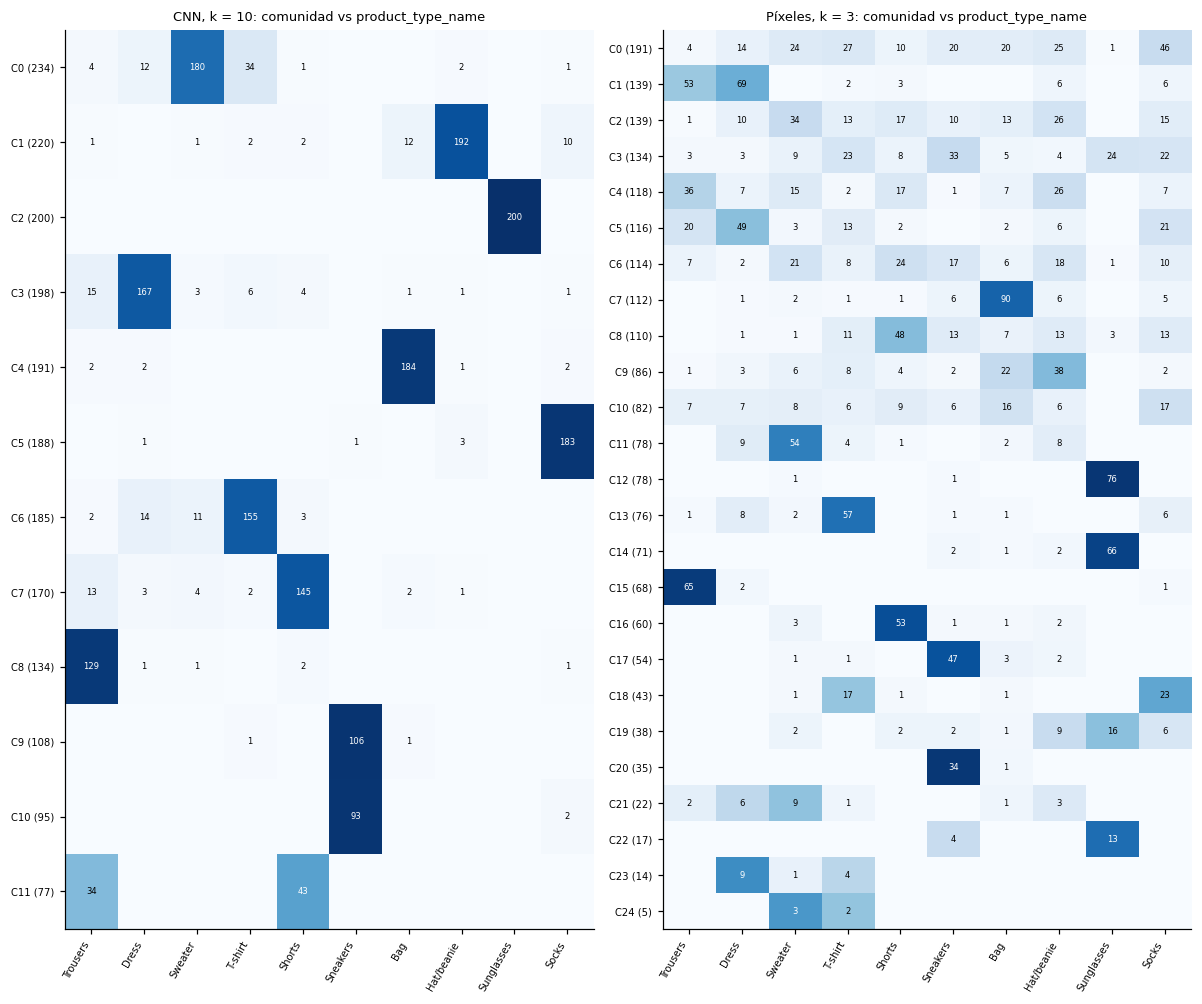

In [20]:
def heatmap(ax, t, titulo):
    frac = t.div(t.sum(axis=1), axis=0)           # proporción dentro de cada comunidad
    ax.imshow(frac.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            if v: ax.text(j, i, v, ha="center", va="center", fontsize=5.5,
                          color="white" if frac.values[i, j] > .55 else "black")
    ax.set_xticks(range(t.shape[1]), t.columns, rotation=60, ha="right", fontsize=6.5)
    ax.set_yticks(range(t.shape[0]), [f"C{c} ({n})" for c, n in zip(t.index, t.sum(axis=1))], fontsize=6.5)
    ax.set_title(titulo, fontsize=8.5)

def figura_contingencia(att, nombre):
    alto = max(CT[(r, att)].shape[0] for r in REPS)
    fig, ejes = plt.subplots(1, 2, figsize=(11, 0.28 * alto + 2.2))
    etiqueta = "product_type_name" if att == "tipo" else "perceived_colour_master_name"
    for ax, rep in zip(ejes, REPS):
        heatmap(ax, CT[(rep, att)], f"{rep}, k = {MEJOR_K[rep]}: comunidad vs {etiqueta}")
    fig.tight_layout(); guardar(fig, nombre); plt.show()

figura_contingencia("tipo", "fig07_contingencia_tipo")

En CNN cada comunidad tiene un tipo dominante y la pureza ponderada es de 0.888. Por cobertura, Sunglasses y Sneakers quedan recuperados al 100 %, Hat/beanie al 96 %, Shorts al 94 % y Bag y Socks al 92 %. La mezcla se concentra en tres comunidades:

1. C0 reúne 180 Sweater con 34 T-shirt y 12 Dress.
2. C6 reúne 155 T-shirt con 14 Dress y 11 Sweater.
3. C11 junta 43 Shorts con 34 Trousers.

Por esa última, Trousers es el tipo con menor cobertura (64 %). En píxeles la pureza ponderada baja a 0.504, y la cobertura va de 19 % en Hat/beanie a 86 % en Sunglasses. Solo C7 (Bag), C12 y C14 (Sunglasses), C15 (Trousers), C16 (Shorts) y C17 y C20 (Sneakers) tienen un tipo claro, y las comunidades grandes, como C0, C2, C3 y C6, mezclan los diez tipos.

Figura 8: **Tabla de contingencia comunidad frente a perceived_colour_master_name**

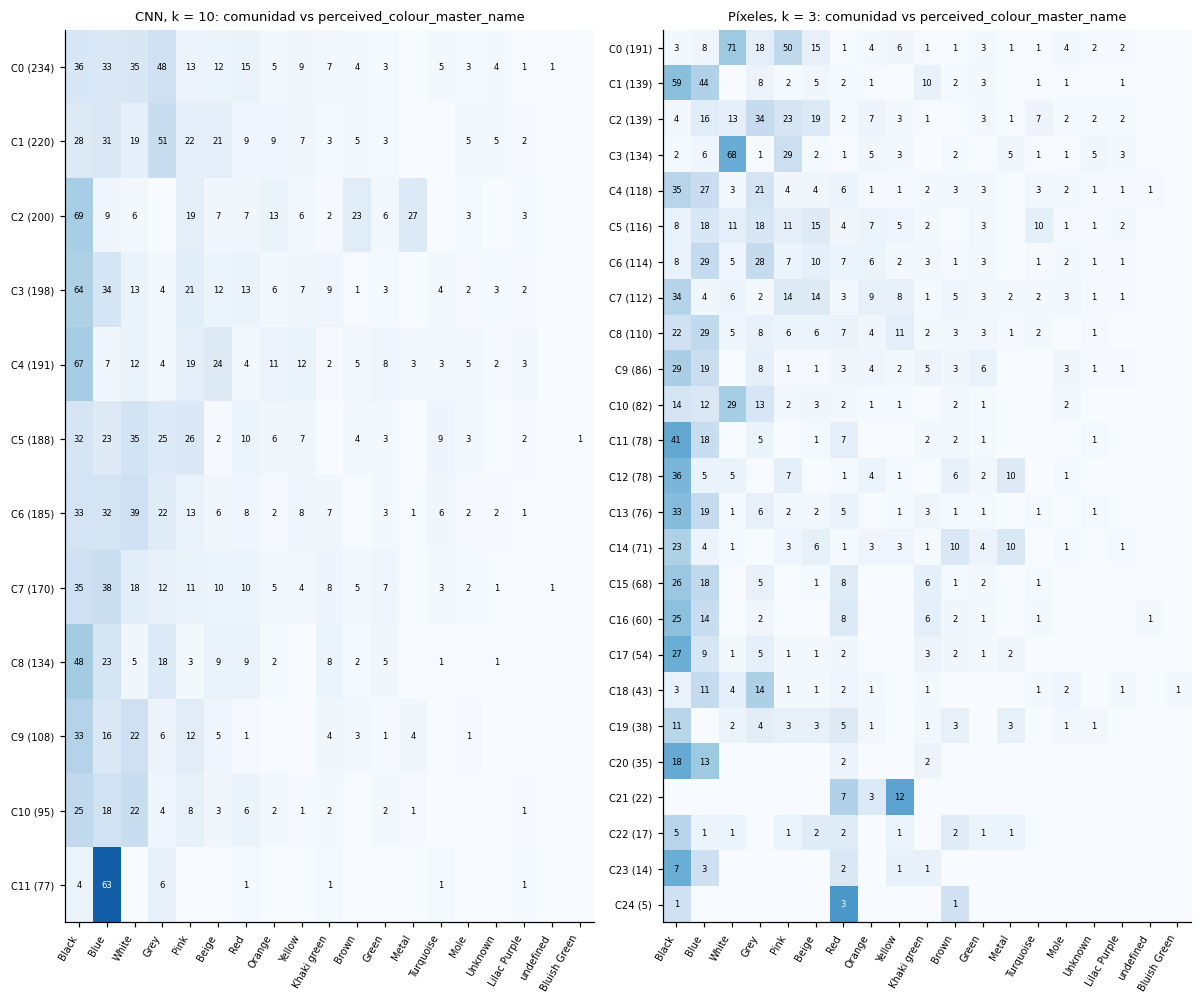

In [21]:
figura_contingencia("color", "fig08_contingencia_color")

En CNN casi todas las comunidades repiten la distribución global de colores, con el negro como color dominante seguido de azul, blanco y gris. Hay dos excepciones, y ninguna se explica por el color en sí:

1. C2 (gafas) acumula Metal y Brown por las monturas.
2. C11 es 82 % azul porque el 82 % de sus artículos tiene patrón **Denim**: es la comunidad de los shorts y jeans de mezclilla, y concentra 63 de los 102 artículos denim de la muestra.

En píxeles el color sí separa. C0 y C3 reúnen blancos y rosados (71 y 68 blancos), en C1, C11, C15 y C16 predominan negros y azules (entre 65 % y 76 %), y C21 concentra los amarillos y rojos.

### 5.2 ARI y NMI frente al catálogo

| Representación | k | Comunidades | Q | ARI tipo | NMI tipo | ARI color | NMI color | NMI patrón |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| CNN, Louvain | 10 | 12 | 0.836 | **0.739** | **0.796** | 0.026 | 0.094 | 0.175 |
| Píxeles, Louvain | 3 | 25 | 0.813 | 0.164 | 0.347 | 0.052 | **0.168** | 0.110 |

Con la CNN las comunidades reproducen el tipo de prenda y son prácticamente independientes del color. Con los píxeles el acuerdo con el tipo es bajo y el acuerdo con el color es casi el doble que en CNN, aunque sigue siendo modesto. El patrón gráfico (graphical_appearance_name, por ejemplo Solid, Stripe o Denim) solo aparece con claridad en la comunidad denim de la CNN.

Para la pregunta sobre el fondo se resume el indicador de fondo blanco por tipo de prenda.

In [22]:
# Proxy de fondo: fracción de píxeles casi blancos en el borde de la foto, por tipo de prenda.
resumen_fondo = (muestra.groupby("product_type_name").fondo_blanco
                 .agg(["mean", lambda s: (s < .5).mean()]).set_axis(["fondo_blanco_medio", "frac_fondo_no_blanco"], axis=1)
                 .loc[TIPOS])
resumen_fondo.round(2)

,fondo_blanco_medio,frac_fondo_no_blanco
product_type_name,,
Trousers,0.81,0.06
Dress,0.83,0.06
Sweater,0.86,0.07
T-shirt,0.83,0.11
Shorts,0.85,0.12
Sneakers,0.88,0.05
Bag,0.81,0.14
Hat/beanie,0.94,0.03
Sunglasses,0.91,0.01


Entre el 81 % y el 94 % del borde de las fotos es casi blanco en todos los tipos, y solo del 1 % al 14 % de las fotos tienen mayoritariamente fondo no blanco (sobre todo Bag, Shorts y T-shirt). En esta muestra casi no hay fotos con modelo: H&M fotografía la prenda sola.

Figura 9: **Imágenes de ejemplo de cinco comunidades CNN y tres de píxeles (siete artículos del tipo mayoritario y hasta tres de otros tipos)**

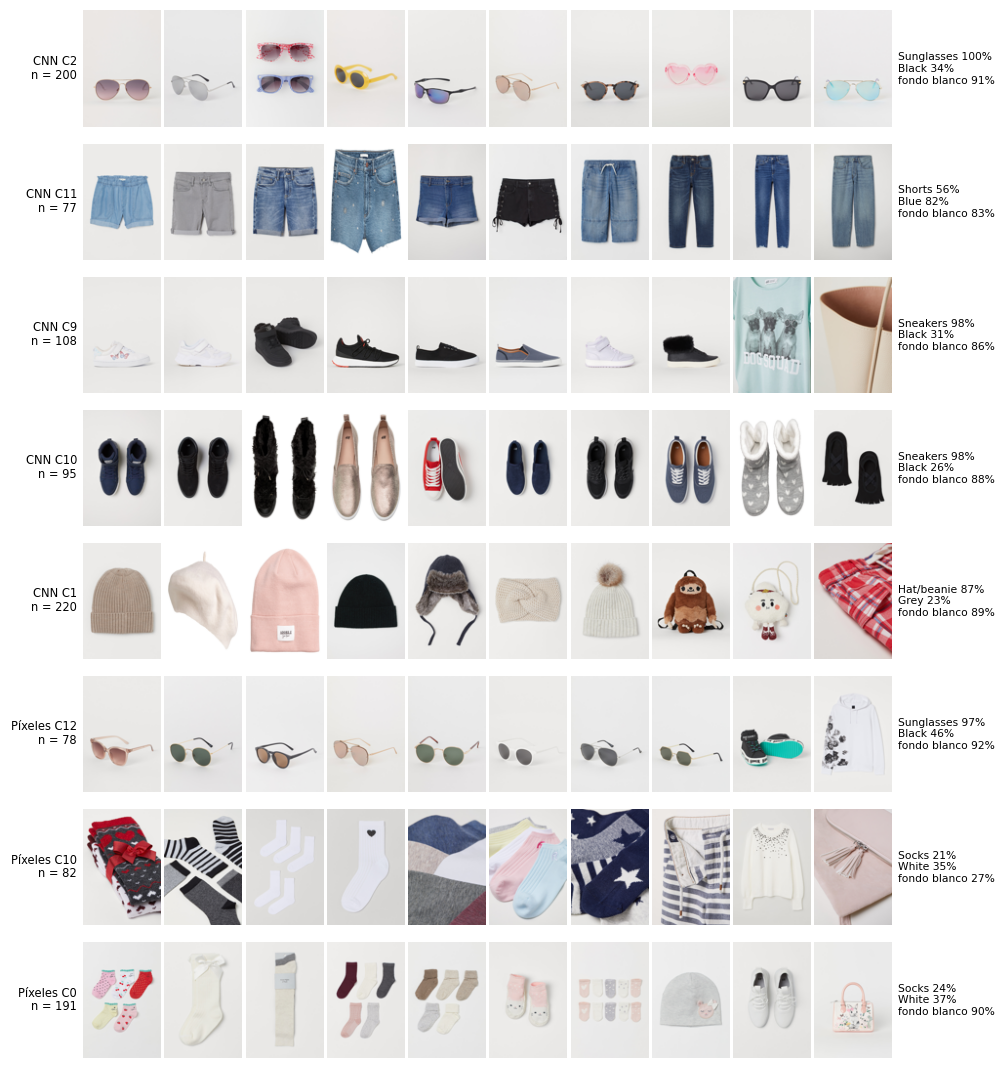

In [23]:
def pureza(t):
    return (t.max(axis=1) / t.sum(axis=1))

def elegir_cnn():
    """La comunidad más pura, la más mezclada, las dos con más Sneakers y la de Hat/beanie."""
    t = CT[("CNN", "tipo")]; p = pureza(t)[t.sum(axis=1) >= 40]
    cand = [p.idxmax(), p.idxmin()] + list(t["Sneakers"].nlargest(2).index) + [t["Hat/beanie"].idxmax()]
    return list(dict.fromkeys(cand))

def elegir_pix():
    """La comunidad más pura, la de menor fracción de fondo blanco y la más grande."""
    t = CT[("Píxeles", "tipo")]; p = pureza(t)[t.sum(axis=1) >= 40]
    e = COM[("Píxeles", MEJOR_K["Píxeles"])]
    fb = pd.Series(muestra.fondo_blanco.values).groupby(e).mean()[p.index]
    return list(dict.fromkeys([p.idxmax(), fb.idxmin(), t.sum(axis=1).idxmax()]))

EJEMPLOS = {"CNN": elegir_cnn(), "Píxeles": elegir_pix()}
filas_fig = [(rep, c) for rep, cs in EJEMPLOS.items() for c in cs]
fig, ejes = plt.subplots(len(filas_fig), 10, figsize=(10, 1.55 * len(filas_fig)))
rs = np.random.default_rng(1)
for i, (rep, c) in enumerate(filas_fig):
    e = COM[(rep, MEJOR_K[rep])]; miembros = np.flatnonzero(e == c)
    # siete artículos del tipo mayoritario y hasta tres de otros tipos, para que se vea la mezcla
    mayor = CT[(rep, "tipo")].loc[c].idxmax()
    may = miembros[y_tipo[miembros] == mayor]; otros = miembros[y_tipo[miembros] != mayor]
    n_otros = min(3, len(otros))
    sel = np.concatenate([rs.choice(may, size=min(10 - n_otros, len(may)), replace=False),
                          rs.choice(otros, size=n_otros, replace=False)]).astype(int)
    t = CT[(rep, "tipo")].loc[c]; tc = CT[(rep, "color")].loc[c]
    fb = muestra.fondo_blanco.values[miembros].mean()
    for j in range(10):
        ax = ejes[i, j]; ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if j < len(sel):
            ax.imshow(Image.open(BASE / muestra.ruta[sel[j]]).convert("RGB").resize((80, 120)))
    ejes[i, 0].set_ylabel(f"{rep} C{c}\nn = {len(miembros)}", rotation=0, ha="right", va="center", fontsize=7.5)
    ejes[i, 9].text(1.08, .5, f"{t.idxmax()} {t.max() / t.sum():.0%}\n{tc.idxmax()} {tc.max() / tc.sum():.0%}\nfondo blanco {fb:.0%}",
                    transform=ejes[i, 9].transAxes, fontsize=7, va="center")
fig.subplots_adjust(wspace=.05, hspace=.12, right=.86)
guardar(fig, "fig09_ejemplos_comunidades"); plt.show()

Las cinco comunidades CNN de la figura muestran cinco formas distintas de agrupar:

1. **C2** son solo gafas de sol, de cualquier color.
2. **C11** es la comunidad más mezclada por tipo, pero muy homogénea por material: shorts y jeans de mezclilla. La CNN reconoce la textura del denim y la antepone al largo de la prenda.
3. **C9 y C10** son las dos comunidades de Sneakers y se distinguen por el **punto de vista**. C9 tiene zapatillas de perfil y C10 el par visto desde arriba, junto con botines y calcetines tobilleros fotografiados igual.
4. **C1** son gorros, a los que se suman mochilas y bolsos de peluche o de punto, con una textura similar.

En píxeles, C12 reúne gafas sobre fondo blanco, pero se cuelan una sudadera blanca y unas zapatillas. C10 es la comunidad de los primeros planos (solo 27 % de fondo blanco): calcetines, tela y bolsos fotografiados de cerca. C0 junta objetos claros y pequeños de cualquier tipo.

### 5.3 Respuestas

**1. ¿Las comunidades detectadas coinciden con los tipos de prenda? ¿En qué medida y con qué representación?**

Sí, con la CNN y en buena medida. Con k = 10 hay 12 comunidades para 10 tipos, con ARI de 0.739, NMI de 0.796 y pureza ponderada de 0.888 (Figuras 4 y 7). Al asignar cada comunidad a su tipo mayoritario, siete de los diez tipos se recuperan en al menos un 90 %. Las dos comunidades sobrantes tienen explicación visual: Sneakers se divide según el punto de vista, y aparece una comunidad de denim. Además, la partición por tipo tiene una Q de 0.762 en ese grafo, cerca de la Q de 0.836 que obtiene Louvain. Con píxeles la coincidencia es baja: ARI de 0.164, NMI de 0.347, pureza de 0.504 y 25 comunidades, de las que solo siete tienen un tipo claro.

**2. ¿Las comunidades agrupan por forma, por color o por otra característica?**

Depende del espacio. Las comunidades CNN agrupan sobre todo por **forma**, y en segundo lugar por **material y textura** y por **punto de vista**. La comunidad C11 reúne el 62 % del denim de la muestra aunque mezcla shorts y pantalones, y Sneakers se parte entre fotos de perfil y fotos desde arriba. El color casi no influye: el NMI con el color es de 0.094 y cada comunidad tiene la misma mezcla de colores que el catálogo, salvo la de denim, que es azul por su material (Figuras 8 y 9). Las comunidades de píxeles agrupan por **luminosidad y color dominante**, y en segundo lugar por silueta y encuadre. Su NMI con el color (0.168) casi duplica al de la CNN, y hay comunidades de prendas oscuras, de prendas claras y de primeros planos.

**3. ¿Qué tipos se mezclan y cuáles quedan claramente separados? ¿Por qué?**

En CNN quedan separados Sunglasses (aislada del resto del grafo hasta k = 5) y Sneakers, ambos con 100 % de cobertura, además de Hat/beanie, Socks y Bag, que superan el 90 %. Todos tienen una silueta única: objeto horizontal pequeño, par de piezas, forma redondeada o asa. Se mezclan tres pares:

1. Sweater con T-shirt: 34 camisetas en la comunidad de suéteres y 11 suéteres en la de camisetas.
2. Dress con ambos y con Trousers.
3. Shorts con Trousers dentro de la comunidad denim.

La explicación es visual. Las fotos muestran la prenda sola sobre el mismo fondo gris claro: entre el 81 % y el 94 % del borde es blanco en todos los tipos y prácticamente no hay fotos con modelo. Como el fondo no discrimina, quedan la silueta y la textura. Una camiseta de manga larga y un suéter fotografiados planos tienen casi la misma silueta, y un jean y un short de mezclilla comparten tela, color y costuras. En píxeles, en cambio, el fondo y la luz sí pesan: los pocos primeros planos o fotos con fondo de color terminan juntos en C10 sin importar el tipo, y las prendas claras y pequeñas se agrupan en C0.

**4. ¿Cómo influye k en la estructura del grafo y en las comunidades?**

Al pasar de k = 3 a k = 20, las aristas aumentan de unas 4800 a unas 30 000, la densidad de 0.002 a 0.015 y el grado medio de 5 a 30 (Figura 2). Con más aristas entre grupos, Q baja (de 0.871 a 0.817 en CNN y de 0.813 a 0.680 en píxeles) y Louvain fusiona comunidades (de 17 a 11 y de 25 a 12). Un k pequeño fragmenta el grafo: con k = 3 y k = 5 el grafo CNN tiene dos componentes y los tipos se parten en subgrupos. Un k grande une regiones vecinas: con k = 20 la comunidad denim se disuelve entre Shorts y Trousers.

En CNN el NMI sube de 0.736 a 0.807, pero el codo está en k = 10. Duplicar las aristas para llegar a k = 20 solo aporta un 1.4 % más de NMI y oculta la comunidad denim. En píxeles conviene el k más bajo, porque los vecinos extra son de otros tipos y diluyen las comunidades (el NMI baja de 0.347 a 0.285).

**5. ¿En qué difieren Louvain y K-Means sobre los mismos vectores? ¿Por qué cabe esperar diferencias?**

En CNN se parecen mucho: el ARI entre ambas particiones es de 0.806. K-Means queda algo por encima frente al tipo (ARI de 0.782 frente a 0.739 y NMI de 0.821 frente a 0.796) porque recibe K = 10, el número exacto de tipos, y no crea comunidades de Sneakers ni de denim. Louvain logra más Q en el grafo (0.836 frente a 0.814) porque es lo que optimiza, y sus grupos son más desiguales (de 77 a 234 artículos, frente a 162 a 250). En píxeles difieren mucho: el ARI entre ambas es de 0.230. Louvain supera a K-Means en NMI (0.347 frente a 0.210) y en Q (0.813 frente a 0.670), y K-Means produce grupos muy desiguales, de 536, 378 y 49 artículos (Figura 5). Las diferencias son esperables por tres razones:

1. Louvain solo ve relaciones locales y no le importa la escala de las distancias, mientras que K-Means compara cada punto con un centroide global y supone grupos esféricos de varianza parecida.
2. Louvain decide el número de grupos y puede formar grupos de cualquier forma, mientras que K-Means recibe K fijo.
3. En 3072 dimensiones de píxeles, la distancia euclidiana a los centroides la domina el brillo global, y eso genera los grupos gigantes de imágenes claras y oscuras.

**6. Diferencia entre los tres espacios: píxeles, embeddings CNN y Node2Vec**

1. **Píxeles:** el vector es la imagen misma. Dos artículos están cerca si tienen los mismos colores en las mismas posiciones, de modo que la distancia mide intensidad y encuadre, no contenido. Desplazar la prenda o cambiarle el color la aleja. En la práctica sirve para encontrar duplicados o fotos con la misma composición, pero no tipos de prenda (K-Means: NMI de 0.210 con el tipo y de 0.172 con el color).
2. **Embeddings CNN:** el vector resume qué patrones visuales detecta una red entrenada para reconocer objetos (bordes, texturas, partes y siluetas) y es bastante invariante a la posición y al color. La distancia coseno mide parecido semántico, por lo que el mismo K-Means pasa a un NMI de 0.821 con el tipo y de 0.080 con el color. Es el espacio adecuado para construir el grafo.
3. **Node2Vec:** el vector no se calcula a partir de la imagen, sino de la posición del nodo en el grafo KNN. Dos artículos quedan cerca si coinciden a menudo en las mismas caminatas aleatorias, es decir, si pertenecen a la misma región del grafo. Hereda la calidad del grafo del que sale (NMI de 0.828 y la mejor Q de K-Means, 0.832) y la comprime en 64 dimensiones, lo que ayuda a visualizar y agrupar (Figura 6). Como contrapartida, depende de k y de la métrica y es transductivo: un artículo nuevo obliga a recalcular el grafo y las caminatas, y no hay forma de volver del vector a la imagen.